# Phishing URL Detection — URL-only Machine Learning

Notebook นี้สร้างระบบจำแนก URL โดยไม่เปิดเว็บไซต์ ไม่ดาวน์โหลด HTML ไม่รัน JavaScript และไม่ติดตาม redirect

ผลลัพธ์สำหรับผู้ใช้มี 3 ระดับ: **Legitimate / Suspicious / Phishing**  
โมเดลเรียนรู้จริงแบบ Binary Classification: `0 = Phishing`, `1 = Legitimate` ส่วน Suspicious คือบริเวณที่โมเดลไม่มั่นใจ ซึ่งกำหนดจาก Validation Set

Dataset: **PhiUSIIL_Phishing_URL_Dataset.csv**  
แหล่งข้อมูล: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset


## Changelog (2026-09-19) — ทดลอง "เอียงโมเดลไปทาง Phishing" ตามที่ปรึกษาอาจารย์

จุดเริ่ม: ทดสอบ `https://rnicrosoft.com` แล้วโมเดลบอกว่า Legitimate ทั้งที่เป็น Phishing (typosquat ของ microsoft.com ที่แทน "m" ด้วย "rn") อาจารย์แนะนำ 2 ทาง คือ (1) เพิ่มข้อมูลฝั่ง Phishing หรือ (2) เอียงโมเดลไปทาง Phishing โดยตั้งใจ — รอบนี้ทำทาง (2) ก่อน ยังไม่แตะเรื่องข้อมูลเพิ่ม

แก้ไป 2 จุด มีคอมเมนต์ `# >>> [EDIT 2026-09-19] ... <<<` กำกับไว้ในทุกเซลล์ที่แก้ ค้นคำว่า `[EDIT` ในโน้ตบุ๊กเพื่อดูจุดที่เปลี่ยนทั้งหมดได้:

1. **Sample weight ฝั่ง Phishing** — เพิ่มตัวแปร `PHISHING_WEIGHT` เป็นตัวคูณน้ำหนักแถว label=0 ตอนเทรน ใช้กับทุกโมเดลที่รองรับ sample_weight (Decision Tree, Gaussian Naive Bayes, Random Forest, XGBoost, Linear SVM) ส่วน KNN ที่ไม่รองรับ sample_weight จะ oversample แถว Phishing แทนด้วยตัวคูณเดียวกัน — แก้ที่เซลล์ตั้งค่าคงที่, เซลล์ helper ใหม่ (`make_sample_weight` / `oversample_phishing` / `fit_with_phishing_weight`), เซลล์ tuning (ข้อ 7) และเซลล์ train เต็มชุด (ข้อ 8)
2. **ขยับ threshold ไปทาง Recall แทน F1** — เพิ่ม `THRESHOLD_MODE` และ `TARGET_PHISHING_RECALL` ให้เลือกได้ว่าจะหา threshold แบบเดิม (F1 สูงสุด) หรือแบบใหม่ (threshold ต่ำสุดที่ยังทำ Recall_Phishing ถึงเป้าที่ตั้งไว้) — แก้ที่เซลล์ฟังก์ชันในข้อ 10 (`find_balanced_suspicious_band` / `find_recall_targeted_threshold` / `build_suspicious_config`)

**ค่าเริ่มต้นที่ตั้งให้ลองก่อน**: `PHISHING_WEIGHT = 5.0`, `THRESHOLD_MODE = "recall_target"`, `TARGET_PHISHING_RECALL = 0.97` — ปรับตัวเลขพวกนี้แล้วรันใหม่ตั้งแต่เซลล์ import ได้เลย เพื่อดู trade-off ระหว่าง Recall ของ Phishing กับ False Positive ฝั่ง Legitimate (ตั้ง `PHISHING_WEIGHT = 1.0` และ `THRESHOLD_MODE = "f1_optimal"` เพื่อกลับไปพฤติกรรมเดิมได้ตลอด)

**เพิ่มเติมในข้อ 11 (Sanity Check)**: ใส่คู่ `microsoft.com` / `rnicrosoft.com` เข้าไปเพื่อเช็คว่าหลังปรับแล้ว จับเคสนี้ได้ดีขึ้นหรือไม่ และในข้อ 13 (บันทึกโมเดล) บันทึก `PHISHING_WEIGHT`/`THRESHOLD_MODE`/`TARGET_PHISHING_RECALL` ที่ใช้เทรนไว้ใน `.joblib` ด้วย เพื่อ track ย้อนหลังได้ว่าโมเดลไฟล์นี้เทรนด้วย config ไหน

**ยังไม่ได้แก้ / ข้อควรระวังที่ยังอยู่เหมือนเดิม**: ฟีเจอร์ 13 ตัวที่ใช้อยู่ยังจับ pattern แบบ `rnicrosoft.com` เทียบ `microsoft.com` ไม่ได้ตรงๆ เพราะสองโดเมนนี้ได้ค่าฟีเจอร์เกือบเหมือนกันทุกตัว (ต่างแค่ความยาว/จำนวนตัวอักษร ±1) การเอียง weight/threshold รอบนี้จะเพิ่ม Recall ของ Phishing โดยรวมและอาจช่วยเคสก้ำกึ่งบางเคสได้ แต่ไม่ได้แก้ blind spot นี้ตรงๆ — ถ้าจะแก้เคสนี้จริงต้องเพิ่ม feature ใหม่ (edit-distance กับ domain ดัง หรือ character n-gram) ซึ่งเป็นงานคนละส่วน


## Requirement ที่ใช้ใน Notebook

- ใช้เฉพาะ URL ที่ผู้ใช้กรอก ไม่ส่ง request ไปยังเว็บปลายทาง
- สร้าง URL-only features 18 ตัวขึ้นใหม่จากข้อความ URL แล้วใช้ชุดลด Bias 13 ตัวเป็นค่าเริ่มต้น
- ลบ URL ซ้ำก่อนแบ่งข้อมูล
- แบ่งข้อมูลแบบ Stratified: Train 56% / Validation 14% / Test 30%
- เปรียบเทียบ 6 โมเดล: KNN, Decision Tree, Gaussian Naive Bayes, Random Forest, XGBoost และ Linear SVM
- KNN ใช้น้ำหนักแบบ uniform เท่านั้น — ไม่มี Modified/Distance-Weighted KNN
- Normalize `www.`, root slash, fragment และ Markdown link ก่อนสร้าง Feature
- ไม่ใช้ PCA, SVD หรือ Character N-Gram ในเวอร์ชันแรก
- เลือกโมเดลจาก F1-score ของ Phishing; หากใกล้กันใช้ Recall ของ Phishing
- จำกัด Hyperparameter tuning เป็นชุดเล็กเพื่อเหมาะกับ Colab
- Test Set ใช้ประเมินหลังเลือกโมเดลจาก Validation Set แล้ว
- Demo ใช้ช่องกรอกและปุ่มภายใน Notebook และแสดงเฉพาะชื่อ Class

**[แก้ 2026-09-19]** เพิ่มตัวเลือกเอียงโมเดลไปทาง Phishing แบบเปิด/ปิดได้ (ดู Changelog ด้านบนสุด): ปรับน้ำหนักตอนเทรนด้วย `PHISHING_WEIGHT` และเปลี่ยนวิธีเลือก threshold ด้วย `THRESHOLD_MODE` / `TARGET_PHISHING_RECALL`


In [29]:
# Colab มีไลบรารีส่วนใหญ่อยู่แล้ว ติดตั้ง/อัปเดตเฉพาะ XGBoost
%pip -q install xgboost


In [30]:
import ipaddress
import json
import re
import time
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TUNE_TRAIN_LIMIT = 50_000
TUNE_VALIDATION_LIMIT = 15_000
TARGET_SUSPICIOUS_RATE = 0.10

# >>> [EDIT 2026-09-19] ตัวเลือกที่ 1+2: เอียงโมเดลไปทาง Phishing โดยตั้งใจ (ดู Changelog ด้านบนสุด) <<<
PHISHING_WEIGHT = 5.0             # ตัวคูณน้ำหนัก/oversample ให้แถว Phishing (label=0) ตอนเทรน; 1.0 = ปิดการเอียง (พฤติกรรมเดิม)
THRESHOLD_MODE = "recall_target"  # "f1_optimal" = พฤติกรรมเดิม, "recall_target" = เลือก threshold จาก TARGET_PHISHING_RECALL แทน
TARGET_PHISHING_RECALL = 0.91     # ใช้เฉพาะตอน THRESHOLD_MODE == "recall_target"
# <<< [END EDIT] >>>

print("พร้อมใช้งาน")


พร้อมใช้งาน


In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1) โหลด Dataset

วางไฟล์ `PhiUSIIL_Phishing_URL_Dataset.csv` ไว้ใน `/content` หรือกดอัปโหลดเมื่อ Cell นี้ร้องขอ  
Notebook อ่านเฉพาะ `URL` และ `label` แล้วสร้าง Features ใหม่เอง เพื่อให้ URL ใหม่ใช้สูตรเดียวกับข้อมูล Train


In [32]:
DATA_PATH = Path("/content/drive/MyDrive/pattern-recognition/phiusiil+phishing+url+dataset/PhiUSIIL_Phishing_URL_Dataset.csv")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("กรุณาอัปโหลด PhiUSIIL_Phishing_URL_Dataset.csv")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("ยังไม่ได้อัปโหลดไฟล์")
        uploaded_name = next(iter(uploaded))
        DATA_PATH = Path("/content") / uploaded_name
    except ImportError as exc:
        raise FileNotFoundError(
            "ไม่พบ Dataset กรุณาแก้ DATA_PATH ให้ชี้ไปยังไฟล์ CSV"
        ) from exc

df = pd.read_csv(DATA_PATH, usecols=["URL", "label"])
print(f"ไฟล์: {DATA_PATH.name}")
print(f"ข้อมูลเริ่มต้น: {df.shape[0]:,} แถว")
display(df.head())


ไฟล์: PhiUSIIL_Phishing_URL_Dataset.csv
ข้อมูลเริ่มต้น: 235,795 แถว


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


## 2) ทำความสะอาดและลบ URL ซ้ำ

การลบก่อน Split ป้องกัน URL เดียวกันหลุดไปอยู่ทั้ง Train และ Test ซึ่งจะทำให้คะแนนสูงเกินจริง


In [33]:
before = len(df)
df = df.dropna(subset=["URL", "label"]).copy()
df["URL"] = df["URL"].astype(str).str.strip()
df = df[df["URL"].ne("")]
df["label"] = df["label"].astype(int)

invalid_labels = sorted(set(df["label"]) - {0, 1})
if invalid_labels:
    raise ValueError(f"พบ label ที่ไม่ใช่ 0/1: {invalid_labels}")

duplicate_count = int(df.duplicated(subset="URL").sum())
df = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)

print(f"ลบ URL ซ้ำ: {duplicate_count:,} แถว")
print(f"คงเหลือ: {len(df):,} แถว จากเดิม {before:,} แถว")
print("\nจำนวนแต่ละ Class")
print(df["label"].value_counts().rename(index={0: "Phishing (0)", 1: "Legitimate (1)"}))


ลบ URL ซ้ำ: 425 แถว
คงเหลือ: 235,370 แถว จากเดิม 235,795 แถว

จำนวนแต่ละ Class
label
Legitimate (1)    134850
Phishing (0)      100520
Name: count, dtype: int64


### ตรวจ Dataset Bias ก่อน Train

ตารางนี้สำคัญกว่าคะแนน Accuracy อย่างเดียว หากรูปแบบการเก็บ URL แยกสอง Class ชัดเกินไป โมเดลอาจเรียนทางลัดแทนพฤติกรรม Phishing จริง


In [34]:
def has_path_or_query(url):
    raw_url = str(url).strip()
    parse_target = raw_url if "://" in raw_url else "http://" + raw_url
    parsed = urlsplit(parse_target)
    return (parsed.path not in ("", "/")) or bool(parsed.query)


bias_rows = []
for label, group in df.groupby("label"):
    urls = group["URL"].astype(str)
    bias_rows.append(
        {
            "Class": "Phishing (0)" if label == 0 else "Legitimate (1)",
            "Rows": len(group),
            "HTTPS": urls.str.lower().str.startswith("https://").mean(),
            "Has www": urls.str.lower().str.contains(r"://www\.", regex=True).mean(),
            "Ends with /": urls.str.endswith("/").mean(),
            "Has path/query": urls.map(has_path_or_query).mean(),
        }
    )

dataset_bias_report = pd.DataFrame(bias_rows)
display(dataset_bias_report.style.format({
    "HTTPS": "{:.2%}",
    "Has www": "{:.2%}",
    "Ends with /": "{:.2%}",
    "Has path/query": "{:.2%}",
}))
print("คำเตือน: Test Set แบบสุ่มยังคงมี Bias แบบเดียวกับ Training Set")


,Class,Rows,HTTPS,Has www,Ends with /,Has path/query
0,Phishing (0),100520,48.63%,41.52%,36.34%,28.17%
1,Legitimate (1),134850,100.00%,100.00%,0.00%,0.00%


คำเตือน: Test Set แบบสุ่มยังคงมี Bias แบบเดียวกับ Training Set


## 3) Normalize URL และสร้าง URL-only Features

หลักสำคัญคือ **คำนวณใหม่จาก URL ทุกแถว** ไม่ใช้ Feature จาก HTML และไม่ใช้สูตรลับที่สร้างซ้ำไม่ได้

- `https://www.google.com`, `https://google.com/` และ Markdown link จะถูก Normalize ให้เป็นรูปแบบเดียวกัน
- lexical text คือ URL หลังตัด scheme และ `www.` ด้านหน้าออก
- Domain/TLD แยกด้วย `urlsplit` โดยไม่เชื่อมต่ออินเทอร์เน็ต
- Obfuscation ในเวอร์ชันนี้หมายถึง percent-encoding เช่น `%2F`
- Feature ที่สะกด `Degits` และ `Spacial` คงชื่อตาม Dataset เพื่อให้ตรวจเทียบง่าย


In [35]:
ALL_URL_FEATURE_NAMES = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS",
]

# ชุดลด Bias/ความซ้ำซ้อนเป็นค่าเริ่มต้น
# ตัด IsHTTPS เพราะ Legitimate ใน Dataset นี้เป็น HTTPS 100%
# ตัด Ratio 4 ตัวที่ซ้ำข้อมูลกับ Count และ Length
REDUCED_FEATURE_NAMES = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
]

USE_REDUCED_FEATURE_SET = True
FEATURE_NAMES = REDUCED_FEATURE_NAMES if USE_REDUCED_FEATURE_SET else ALL_URL_FEATURE_NAMES

PERCENT_ENCODED_PATTERN = re.compile(r"%[0-9A-Fa-f]{2}")
MARKDOWN_URL_PATTERN = re.compile(
    r"^\[[^\]]*\]\((https?://[^)]+)\)$",
    re.IGNORECASE,
)


def normalize_url(url):
    raw_url = str(url).strip()
    if not raw_url:
        raise ValueError("URL ต้องไม่เป็นค่าว่าง")

    markdown_match = MARKDOWN_URL_PATTERN.fullmatch(raw_url)
    if markdown_match:
        raw_url = markdown_match.group(1)

    if "://" not in raw_url:
        raw_url = "http://" + raw_url

    parsed = urlsplit(raw_url)
    scheme = parsed.scheme.lower()
    hostname = (parsed.hostname or "").lower().rstrip(".")
    if not hostname:
        raise ValueError("ไม่พบ Domain ใน URL")

    # ตัด www เพื่อไม่ให้โมเดลใช้รูปแบบการเก็บข้อมูลเป็นทางลัด
    if hostname.startswith("www."):
        hostname = hostname[4:]

    try:
        port = parsed.port
    except ValueError:
        port = None

    netloc = hostname
    is_default_port = (scheme == "http" and port == 80) or (scheme == "https" and port == 443)
    if port is not None and not is_default_port:
        netloc = f"{hostname}:{port}"

    # root slash ไม่มีความหมายเชิงโครงสร้าง จึงทำให้ / และค่าว่างเหมือนกัน
    path = "" if parsed.path == "/" and not parsed.query else parsed.path

    # fragment ไม่ถูกส่งไปยัง web server จึงไม่ใช้เป็น Feature
    return urlunsplit((scheme, netloc, path, parsed.query, ""))


def extract_url_features(url):
    # สร้าง 18 features จากข้อความ URL เท่านั้น ไม่มี network request
    raw_url = normalize_url(url)
    parsed = urlsplit(raw_url)
    hostname = (parsed.hostname or "").lower().rstrip(".")
    scheme = parsed.scheme.lower()

    try:
        ipaddress.ip_address(hostname)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    domain_parts = [part for part in hostname.split(".") if part]
    tld_length = 0 if is_domain_ip or not domain_parts else len(domain_parts[-1])
    no_of_subdomains = 0 if is_domain_ip else max(len(domain_parts) - 2, 0)

    lexical_text = raw_url.split("://", 1)[-1]

    denominator = max(len(lexical_text), 1)
    encoded_tokens = PERCENT_ENCODED_PATTERN.findall(lexical_text)
    no_of_obfuscated = len(encoded_tokens)
    no_of_letters = sum(char.isalpha() for char in lexical_text)
    no_of_digits = sum(char.isdigit() for char in lexical_text)

    excluded_special = {"=", "?", "&", "%"}
    no_of_other_special = sum(
        (not char.isalnum()) and char not in excluded_special
        for char in lexical_text
    )

    features = {
        "URLLength": len(raw_url),
        "DomainLength": len(hostname),
        "IsDomainIP": is_domain_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomains,
        "HasObfuscation": int(no_of_obfuscated > 0),
        "NoOfObfuscatedChar": no_of_obfuscated,
        "ObfuscationRatio": no_of_obfuscated / denominator,
        "NoOfLettersInURL": no_of_letters,
        "LetterRatioInURL": no_of_letters / denominator,
        "NoOfDegitsInURL": no_of_digits,
        "DegitRatioInURL": no_of_digits / denominator,
        "NoOfEqualsInURL": lexical_text.count("="),
        "NoOfQMarkInURL": lexical_text.count("?"),
        "NoOfAmpersandInURL": lexical_text.count("&"),
        "NoOfOtherSpecialCharsInURL": no_of_other_special,
        "SpacialCharRatioInURL": no_of_other_special / denominator,
        "IsHTTPS": int(scheme == "https"),
    }
    return features


example_url = "https://paypal-login.example.com/verify?id=123&next=%2Fhome"
display(pd.DataFrame([extract_url_features(example_url)])[FEATURE_NAMES])

# Sanity check: ทั้งสามรูปแบบต้อง Normalize และสร้าง Feature เหมือนกัน
google_variants = [
    "https://www.google.com",
    "https://www.google.com/",
    "https://google.com",
]
normalized_google = [normalize_url(url) for url in google_variants]
google_feature_check = pd.DataFrame(
    [extract_url_features(url) for url in google_variants],
    columns=FEATURE_NAMES,
)
assert len(set(normalized_google)) == 1
assert google_feature_check.nunique().max() == 1
print("Google normalization check: PASS ->", normalized_google[0])


,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,NoOfLettersInURL,NoOfDegitsInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL
0,59,24,0,3,1,1,1,38,4,2,1,1,4


Google normalization check: PASS -> https://google.com


In [36]:
feature_records = [
    extract_url_features(url)
    for url in tqdm(df["URL"], total=len(df), desc="Extracting URL features")
]
all_url_features = pd.DataFrame.from_records(
    feature_records,
    columns=ALL_URL_FEATURE_NAMES,
)
X = all_url_features[FEATURE_NAMES].copy()
y = df["label"].copy()

if X.isna().any().any():
    raise ValueError("พบ Missing Value หลังสร้าง Features")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("พบค่า infinity หลังสร้าง Features")

mode = "Reduced 13 features" if USE_REDUCED_FEATURE_SET else "Full 18 features"
print(f"Feature set: {mode}")
print(f"Feature matrix: {X.shape[0]:,} แถว × {X.shape[1]} features")
display(X.describe().T)


Extracting URL features:   0%|          | 0/235370 [00:00<?, ?it/s]

Feature set: Reduced 13 features
Feature matrix: 235,370 แถว × 13 features


,count,mean,std,min,25%,50%,75%,max
URLLength,235370.0,32.063279,37.762356,11.0,21.0,25.0,32.0,4274.0
DomainLength,235370.0,18.453834,9.842558,4.0,12.0,16.0,21.0,110.0
IsDomainIP,235370.0,0.002575,0.050676,0.0,0.0,0.0,0.0,1.0
TLDLength,235370.0,2.757208,0.613108,0.0,2.0,3.0,3.0,13.0
NoOfSubDomain,235370.0,0.409572,0.673001,0.0,0.0,0.0,1.0,10.0
HasObfuscation,235370.0,0.003624,0.060091,0.0,0.0,0.0,0.0,1.0
NoOfObfuscatedChar,235370.0,0.024404,0.832204,0.0,0.0,0.0,0.0,149.0
NoOfLettersInURL,235370.0,20.050614,24.846827,0.0,11.0,15.0,21.0,2967.0
NoOfDegitsInURL,235370.0,1.859914,11.611870,0.0,0.0,0.0,0.0,2011.0
NoOfEqualsInURL,235370.0,0.062480,0.933722,0.0,0.0,0.0,0.0,176.0


## 4) สำรวจข้อมูลเบื้องต้น

กราฟนี้ใช้เพื่อดูความสมดุลของ Class และความสัมพันธ์ระหว่าง Features ไม่ใช้ Test Set ในการปรับโมเดล


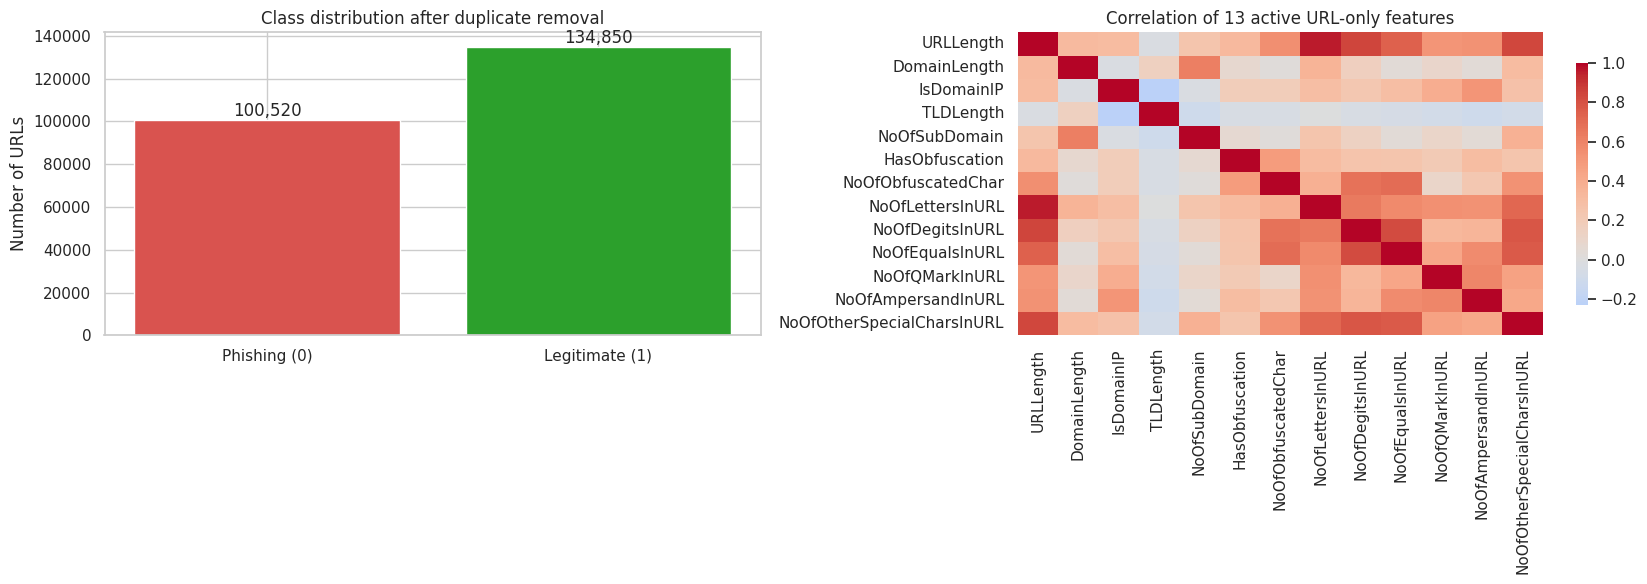

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

class_counts = y.value_counts().sort_index()
axes[0].bar(["Phishing (0)", "Legitimate (1)"], class_counts.values, color=["#d9534f", "#2ca02c"])
axes[0].set_title("Class distribution after duplicate removal")
axes[0].set_ylabel("Number of URLs")
for index, value in enumerate(class_counts.values):
    axes[0].text(index, value, f"{value:,}", ha="center", va="bottom")

sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title(f"Correlation of {len(FEATURE_NAMES)} active URL-only features")
plt.tight_layout()
plt.show()


## 5) แบ่งข้อมูลแบบ Stratified 56/14/30

ขั้นแรกแยก Test 30% ออกก่อน จากนั้นแบ่ง 70% ที่เหลือเป็น Train 80% และ Validation 20% จึงเท่ากับ 56% และ 14% ของข้อมูลทั้งหมด


In [38]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_trainval,
)

split_summary = pd.DataFrame(
    {
        "Rows": [len(X_train), len(X_val), len(X_test)],
        "Percent": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
        "Phishing (0)": [(labels == 0).sum() for labels in (y_train, y_val, y_test)],
        "Legitimate (1)": [(labels == 1).sum() for labels in (y_train, y_val, y_test)],
    },
    index=["Train", "Validation", "Test"],
)
split_summary["Percent"] = (split_summary["Percent"] * 100).round(2).astype(str) + "%"
display(split_summary)


,Rows,Percent,Phishing (0),Legitimate (1)
Train,131807,56.0%,56291,75516
Validation,32952,14.0%,14073,18879
Test,70611,30.0%,30156,40455


## 6) Metric และโมเดล

ใน Dataset นี้ Phishing มี label เป็น 0 ดังนั้น Precision, Recall และ F1 ด้านล่างกำหนด `pos_label=0` อย่างชัดเจน

StandardScaler ใช้กับ KNN และ Linear SVM เพราะโมเดลทั้งสองไวต่อสเกลของ Feature ส่วน Tree-based models และ GaussianNB ไม่ต้องใช้ Scaling


In [39]:
def phishing_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Phishing": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Recall_Phishing": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1_Phishing": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
    }


def build_model(model_name, params):
    if model_name == "KNN":
        return Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    KNeighborsClassifier(
                        n_neighbors=params["n_neighbors"],
                        weights="uniform",
                        n_jobs=-1,
                    ),
                ),
            ]
        )

    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=RANDOM_STATE, **params)

    if model_name == "Gaussian Naive Bayes":
        return GaussianNB(**params)

    if model_name == "Random Forest":
        return RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )

    if model_name == "XGBoost":
        return XGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            eval_metric="logloss",
            colsample_bytree=0.9,
            **params,
        )

    if model_name == "Linear SVM":
        return Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    LinearSVC(
                        random_state=RANDOM_STATE,
                        dual=False,
                        max_iter=10_000,
                        **params,
                    ),
                ),
            ]
        )

    raise ValueError(f"ไม่รู้จักโมเดล: {model_name}")


MODEL_GRIDS = {
    "KNN": {"n_neighbors": [3, 7, 11, 13]},
    "Decision Tree": {"max_depth": [10, None], "min_samples_leaf": [1, 5, 7]},
    "Gaussian Naive Bayes": {"var_smoothing": [1e-9, 1e-8, 1e-7,1e-10]},
    "Random Forest": {
        "n_estimators": [1000],
        "max_depth": [20, None],
        "min_samples_leaf": [1, 3,5],
        "class_weight": [None],
    },
    "XGBoost": {
        "n_estimators": [100],
        "max_depth": [4, 6, 10],
        "learning_rate": [0.075],
        "subsample": [0.90],
    },
    # ค่า C เล็กลงเพื่อเพิ่ม Regularization; ไม่ใช้ class_weight เพราะ Class ไม่ได้ต่างกันรุนแรง
    "Linear SVM": {"C": [0.01, 0.1 ,0.5 , 1.0 , 3.0 , 5.0], "class_weight": [None]},
}

print("จำนวนชุด Hyperparameter")
for name, grid in MODEL_GRIDS.items():
    print(f"- {name}: {len(list(ParameterGrid(grid)))} ชุด")


จำนวนชุด Hyperparameter
- KNN: 4 ชุด
- Decision Tree: 6 ชุด
- Gaussian Naive Bayes: 4 ชุด
- Random Forest: 6 ชุด
- XGBoost: 3 ชุด
- Linear SVM: 6 ชุด


In [40]:
# >>> [EDIT 2026-09-19] Helper ใหม่สำหรับตัวเลือกที่ 1: เอียงน้ำหนักการเทรนไปทาง Phishing (ดู Changelog ด้านบนสุด) <<<
def make_sample_weight(y, weight_for_phishing=1.0):
    """คืนน้ำหนักต่อแถวสำหรับ .fit(..., sample_weight=...):
    label=0 (Phishing) ได้น้ำหนัก weight_for_phishing, label=1 (Legitimate) ได้น้ำหนัก 1.0"""
    y_array = np.asarray(y)
    return np.where(y_array == 0, weight_for_phishing, 1.0)


def oversample_phishing(X, y, weight_for_phishing=1.0, seed=RANDOM_STATE):
    """ใช้แทน sample_weight สำหรับโมเดลที่ไม่รองรับ sample_weight (เช่น KNN)
    ก็อปปีแถว Phishing (label=0) ซ้ำประมาณ weight_for_phishing เท่า
    (จำนวนเต็มก็อปแบบตรงๆ ส่วนเศษสุ่มเลือกบางแถวมาเพิ่มเพื่อให้ได้น้ำหนักเฉลี่ยตรงเป้า)
    """
    if weight_for_phishing <= 1.0:
        return X, y

    rng = np.random.default_rng(seed)
    y_array = np.asarray(y)
    phishing_mask = y_array == 0

    whole_copies = int(weight_for_phishing)
    fractional_part = weight_for_phishing - whole_copies

    X_phishing = X[phishing_mask]
    y_phishing = y_array[phishing_mask]

    extra_parts_X = [X] + [X_phishing] * (whole_copies - 1)
    extra_parts_y = [y_array] + [y_phishing] * (whole_copies - 1)

    if fractional_part > 0:
        extra_rows = rng.random(len(X_phishing)) < fractional_part
        extra_parts_X.append(X_phishing[extra_rows])
        extra_parts_y.append(y_phishing[extra_rows])

    X_oversampled = pd.concat(extra_parts_X, ignore_index=True)
    y_oversampled = pd.Series(np.concatenate(extra_parts_y))
    return X_oversampled, y_oversampled


def fit_with_phishing_weight(model_name, model, X_part, y_part, weight_for_phishing=1.0):
    """เรียก .fit() พร้อมเอียงน้ำหนักไปทาง Phishing ให้เหมาะกับแต่ละโมเดล:
    - KNN: ไม่รองรับ sample_weight -> oversample แถว Phishing แทน
    - Linear SVM: ห่อด้วย Pipeline(steps=[("scaler", ...), ("model", ...)])
      -> ต้องส่ง sample_weight ผ่านชื่อ step ว่า model__sample_weight
    - โมเดลอื่น (Decision Tree, Gaussian Naive Bayes, Random Forest, XGBoost): ส่ง sample_weight ตรงๆ
    """
    if weight_for_phishing == 1.0:
        model.fit(X_part, y_part)
        return model

    if model_name == "KNN":
        X_resampled, y_resampled = oversample_phishing(X_part, y_part, weight_for_phishing)
        model.fit(X_resampled, y_resampled)
        return model

    weights = make_sample_weight(y_part, weight_for_phishing)

    if model_name == "Linear SVM":
        model.fit(X_part, y_part, model__sample_weight=weights)
        return model

    model.fit(X_part, y_part, sample_weight=weights)
    return model


print(f"PHISHING_WEIGHT ที่จะใช้เทรนรอบนี้: {PHISHING_WEIGHT}")
# <<< [END EDIT] >>>


PHISHING_WEIGHT ที่จะใช้เทรนรอบนี้: 5.0


## 7) Hyperparameter tuning แบบจำกัดเวลา

เพื่อให้อยู่ในกรอบประมาณ 30–60 นาที ขั้นตอนค้นหาค่าใช้ตัวอย่างแบบ Stratified จาก Train/Validation  
หลังเลือกค่าที่ดีที่สุดของแต่ละโมเดลแล้ว Cell ถัดไปจะ Train ใหม่ด้วย **Train 56% เต็มชุด** และตรวจบน Validation 14% เต็มชุด


In [41]:
def stratified_limit(X_part, y_part, max_rows, seed_offset=0):
    if max_rows is None or len(X_part) <= max_rows:
        return X_part, y_part
    X_sample, _, y_sample, _ = train_test_split(
        X_part,
        y_part,
        train_size=max_rows,
        random_state=RANDOM_STATE + seed_offset,
        stratify=y_part,
    )
    return X_sample, y_sample


X_tune_train, y_tune_train = stratified_limit(
    X_train, y_train, TUNE_TRAIN_LIMIT, seed_offset=1
)
X_tune_val, y_tune_val = stratified_limit(
    X_val, y_val, TUNE_VALIDATION_LIMIT, seed_offset=2
)

print(f"Tuning train: {len(X_tune_train):,} แถว")
print(f"Tuning validation: {len(X_tune_val):,} แถว")

tuning_rows = []
best_params_by_model = {}

for model_name, grid in MODEL_GRIDS.items():
    print(f"\nกำลังทดลอง {model_name}")
    model_rows = []

    for params in ParameterGrid(grid):
        start = time.perf_counter()
        candidate = build_model(model_name, params)
        # >>> [EDIT 2026-09-19] ตัวเลือกที่ 1: เอียงน้ำหนักไปทาง Phishing ตอน tuning ด้วย <<<
        candidate = fit_with_phishing_weight(
            model_name, candidate, X_tune_train, y_tune_train, PHISHING_WEIGHT
        )
        # <<< [END EDIT] >>>
        predictions = candidate.predict(X_tune_val)
        elapsed = time.perf_counter() - start

        row = {
            "Model": model_name,
            "Parameters": params.copy(),
            "Seconds": elapsed,
            **phishing_metrics(y_tune_val, predictions),
        }
        model_rows.append(row)
        tuning_rows.append(row)
        print(
            f"  {params} -> F1={row['F1_Phishing']:.4f}, "
            f"Recall={row['Recall_Phishing']:.4f}, {elapsed:.1f}s"
        )

    model_rows.sort(
        key=lambda item: (item["F1_Phishing"], item["Recall_Phishing"]),
        reverse=True,
    )
    best_params_by_model[model_name] = model_rows[0]["Parameters"]

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    ["Model", "F1_Phishing", "Recall_Phishing"],
    ascending=[True, False, False],
)
display(tuning_results.reset_index(drop=True))

print("\nค่าที่เลือกของแต่ละโมเดล")
for name, params in best_params_by_model.items():
    print(f"- {name}: {params}")


Tuning train: 50,000 แถว
Tuning validation: 15,000 แถว

กำลังทดลอง KNN
  {'n_neighbors': 3} -> F1=0.9708, Recall=0.9639, 11.7s
  {'n_neighbors': 7} -> F1=0.9686, Recall=0.9652, 11.5s
  {'n_neighbors': 11} -> F1=0.9665, Recall=0.9661, 12.3s
  {'n_neighbors': 13} -> F1=0.9640, Recall=0.9666, 12.5s

กำลังทดลอง Decision Tree
  {'max_depth': 10, 'min_samples_leaf': 1} -> F1=0.8220, Recall=0.9120, 0.1s
  {'max_depth': 10, 'min_samples_leaf': 5} -> F1=0.8206, Recall=0.9134, 0.1s
  {'max_depth': 10, 'min_samples_leaf': 7} -> F1=0.8204, Recall=0.9127, 0.0s
  {'max_depth': None, 'min_samples_leaf': 1} -> F1=0.9677, Recall=0.9705, 0.1s
  {'max_depth': None, 'min_samples_leaf': 5} -> F1=0.9612, Recall=0.9717, 0.1s
  {'max_depth': None, 'min_samples_leaf': 7} -> F1=0.9602, Recall=0.9725, 0.1s

กำลังทดลอง Gaussian Naive Bayes
  {'var_smoothing': 1e-09} -> F1=0.5958, Recall=0.4263, 0.0s
  {'var_smoothing': 1e-08} -> F1=0.6168, Recall=0.4483, 0.0s
  {'var_smoothing': 1e-07} -> F1=0.6456, Recall=0.4811

,Model,Parameters,Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 1}",0.066748,0.972333,0.964923,0.970496,0.967702
1,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5}",0.059667,0.966467,0.950817,0.971745,0.961167
2,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 7}",0.061324,0.965533,0.948105,0.972526,0.960160
3,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 1}",0.054934,0.831333,0.748207,0.911958,0.822006
4,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 5}",0.053675,0.829467,0.744971,0.913362,0.820617
5,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 7}",0.048325,0.829333,0.745031,0.912738,0.820401
6,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.020669,0.774400,0.980904,0.481111,0.645580
7,Gaussian Naive Bayes,{'var_smoothing': 1e-08},0.017727,0.762133,0.988300,0.448330,0.616838
8,Gaussian Naive Bayes,{'var_smoothing': 1e-09},0.018805,0.753000,0.989134,0.426319,0.595833
9,Gaussian Naive Bayes,{'var_smoothing': 1e-10},0.017685,0.747933,0.989922,0.413987,0.583819



ค่าที่เลือกของแต่ละโมเดล
- KNN: {'n_neighbors': 3}
- Decision Tree: {'max_depth': None, 'min_samples_leaf': 1}
- Gaussian Naive Bayes: {'var_smoothing': 1e-07}
- Random Forest: {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 1000}
- XGBoost: {'learning_rate': 0.075, 'max_depth': 10, 'n_estimators': 100, 'subsample': 0.9}
- Linear SVM: {'C': 5.0, 'class_weight': None}


## 8) Train ด้วย Training Set เต็มและเลือกผู้ชนะจาก Validation Set

โมเดลผู้ชนะถูกเลือกก่อนแตะ Test Set โดยเรียงจาก F1 ของ Phishing แล้วใช้ Recall ของ Phishing เป็นตัวตัดสินกรณีคะแนนใกล้กัน


In [42]:
fitted_models = {}
validation_predictions = {}
validation_rows = []

for model_name, params in best_params_by_model.items():
    print(f"กำลัง Train {model_name} ด้วย Training Set เต็ม...")
    start = time.perf_counter()
    model = build_model(model_name, params)
    # >>> [EDIT 2026-09-19] ตัวเลือกที่ 1: เอียงน้ำหนักไปทาง Phishing ตอน train เต็มชุด <<<
    model = fit_with_phishing_weight(model_name, model, X_train, y_train, PHISHING_WEIGHT)
    # <<< [END EDIT] >>>
    predictions = model.predict(X_val)
    elapsed = time.perf_counter() - start

    fitted_models[model_name] = model
    validation_predictions[model_name] = predictions
    validation_rows.append(
        {
            "Model": model_name,
            "Seconds": elapsed,
            **phishing_metrics(y_val, predictions),
        }
    )

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["F1_Phishing", "Recall_Phishing"], ascending=False
).reset_index(drop=True)

selected_model_name = validation_results.loc[0, "Model"]
selected_model = fitted_models[selected_model_name]

display(validation_results.style.format({
    "Seconds": "{:.1f}",
    "Accuracy": "{:.4f}",
    "Precision_Phishing": "{:.4f}",
    "Recall_Phishing": "{:.4f}",
    "F1_Phishing": "{:.4f}",
}))
print(f"\nโมเดลที่เลือกจาก Validation Set: {selected_model_name}")

# ตรวจ Generalization gap แบบเบา ๆ ด้วยตัวอย่างจาก Training Set
X_gap_train, y_gap_train = stratified_limit(
    X_train, y_train, max_rows=15_000, seed_offset=3
)
train_gap_predictions = selected_model.predict(X_gap_train)
train_gap_metrics = phishing_metrics(y_gap_train, train_gap_predictions)
selected_validation_metrics = validation_results.loc[
    validation_results["Model"] == selected_model_name
].iloc[0]
f1_gap = train_gap_metrics["F1_Phishing"] - selected_validation_metrics["F1_Phishing"]

print(f"Training-sample F1: {train_gap_metrics['F1_Phishing']:.4f}")
print(f"Validation F1:      {selected_validation_metrics['F1_Phishing']:.4f}")
print(f"Generalization gap: {f1_gap:.4f}")
print("หมายเหตุ: gap เล็กไม่ได้ลบปัญหา Dataset Bias เพราะ Train/Validation มาจากแหล่งเดียวกัน")


กำลัง Train KNN ด้วย Training Set เต็ม...
กำลัง Train Decision Tree ด้วย Training Set เต็ม...
กำลัง Train Gaussian Naive Bayes ด้วย Training Set เต็ม...
กำลัง Train Random Forest ด้วย Training Set เต็ม...
กำลัง Train XGBoost ด้วย Training Set เต็ม...
กำลัง Train Linear SVM ด้วย Training Set เต็ม...


,Model,Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,KNN,55.1,0.9772,0.9800,0.9662,0.9731
1,Random Forest,48.5,0.9759,0.9723,0.9714,0.9718
2,Decision Tree,0.2,0.9745,0.9690,0.9713,0.9702
3,XGBoost,1.4,0.9724,0.9607,0.9753,0.9679
4,Linear SVM,1.7,0.9632,0.9409,0.9752,0.9577
5,Gaussian Naive Bayes,0.0,0.7723,0.9732,0.4801,0.6430



โมเดลที่เลือกจาก Validation Set: KNN
Training-sample F1: 0.9764
Validation F1:      0.9731
Generalization gap: 0.0033
หมายเหตุ: gap เล็กไม่ได้ลบปัญหา Dataset Bias เพราะ Train/Validation มาจากแหล่งเดียวกัน


## 9) ประเมิน Test Set ครั้งสุดท้าย

ผู้ชนะถูกกำหนดจาก Validation Set แล้ว ตาราง Test ใช้รายงานประสิทธิภาพสุดท้าย ไม่ควรย้อนกลับไปปรับ Hyperparameter จากผลตารางนี้


In [43]:
test_rows = []
test_predictions = {}

for model_name, model in fitted_models.items():
    print(f"กำลังทดสอบ {model_name}...")
    start = time.perf_counter()
    predictions = model.predict(X_test)
    elapsed = time.perf_counter() - start
    test_predictions[model_name] = predictions
    test_rows.append(
        {
            "Model": model_name,
            "Selected_by_Validation": model_name == selected_model_name,
            "Predict_Seconds": elapsed,
            **phishing_metrics(y_test, predictions),
        }
    )

test_results = pd.DataFrame(test_rows).sort_values(
    ["F1_Phishing", "Recall_Phishing"], ascending=False
).reset_index(drop=True)

display(test_results.style.format({
    "Predict_Seconds": "{:.1f}",
    "Accuracy": "{:.4f}",
    "Precision_Phishing": "{:.4f}",
    "Recall_Phishing": "{:.4f}",
    "F1_Phishing": "{:.4f}",
}))
print(f"โมเดลที่กำหนดเป็นผู้ชนะก่อนดู Test: {selected_model_name}")


กำลังทดสอบ KNN...
กำลังทดสอบ Decision Tree...
กำลังทดสอบ Gaussian Naive Bayes...
กำลังทดสอบ Random Forest...
กำลังทดสอบ XGBoost...
กำลังทดสอบ Linear SVM...


,Model,Selected_by_Validation,Predict_Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,KNN,True,105.1,0.9768,0.9813,0.9640,0.9726
1,Random Forest,False,4.3,0.9764,0.9742,0.9704,0.9723
2,Decision Tree,False,0.0,0.9745,0.9709,0.9692,0.9701
3,XGBoost,False,0.3,0.9720,0.9614,0.9735,0.9674
4,Linear SVM,False,0.0,0.9650,0.9459,0.9737,0.9596
5,Gaussian Naive Bayes,False,0.0,0.7743,0.9785,0.4822,0.6460


โมเดลที่กำหนดเป็นผู้ชนะก่อนดู Test: KNN


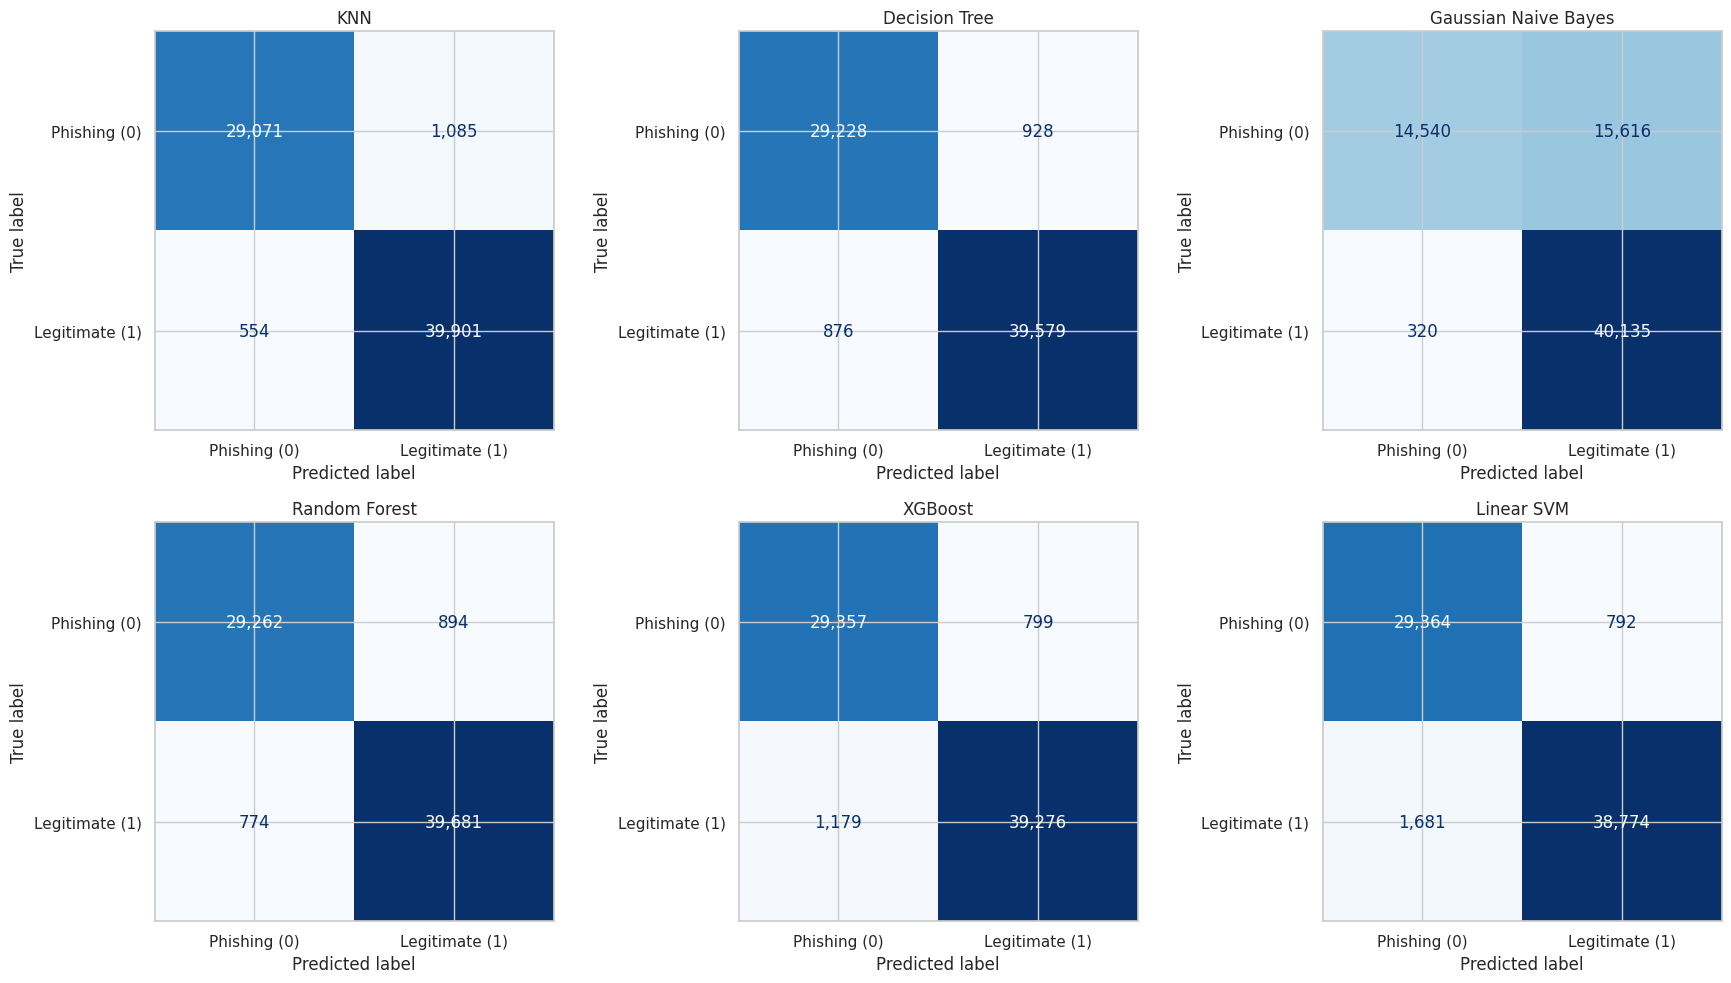

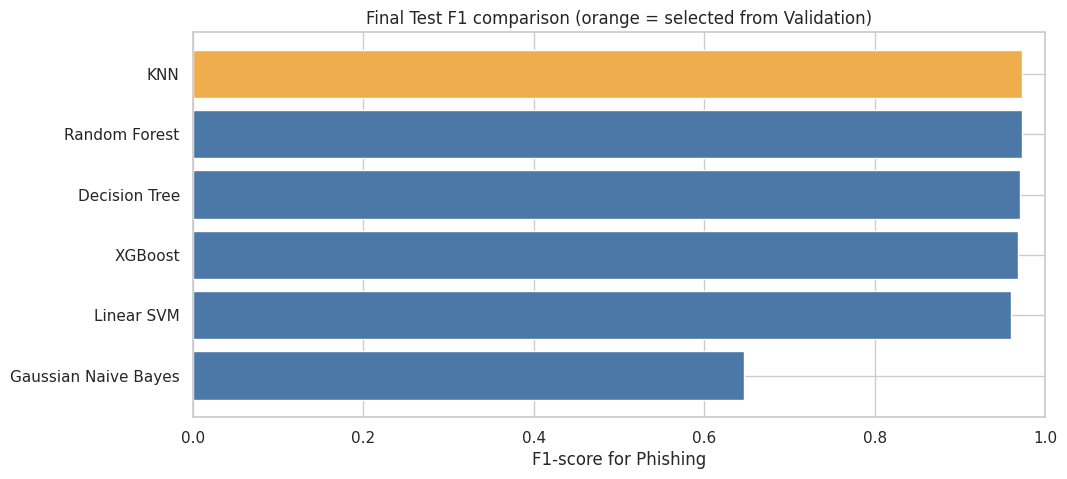

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, model_name in zip(axes, fitted_models):
    matrix = confusion_matrix(y_test, test_predictions[model_name], labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Phishing (0)", "Legitimate (1)"],
    ).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",d")
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
ordered = test_results.sort_values("F1_Phishing", ascending=True)
colors = ["#f0ad4e" if name == selected_model_name else "#4c78a8" for name in ordered["Model"]]
plt.barh(ordered["Model"], ordered["F1_Phishing"], color=colors)
plt.xlim(0, 1)
plt.xlabel("F1-score for Phishing")
plt.title("Final Test F1 comparison (orange = selected from Validation)")
plt.show()


## 10) สร้างช่วง Suspicious จาก Validation Set

1. แปลงผลของโมเดลเป็นคะแนนที่ **ค่ายิ่งสูงยิ่งเสี่ยงเป็น Phishing**
2. หา Binary threshold ที่ทำให้ F1 ของ Phishing บน Validation สูงสุด
3. ใช้ URL ที่มีคะแนนใกล้เส้นแบ่งที่สุดประมาณ 10% เป็น Suspicious

ค่า 10% ปรับได้ด้วย `TARGET_SUSPICIOUS_RATE` ที่ Cell ตั้งค่า โดยไม่แสดงคะแนนนี้แก่ผู้ใช้

**[แก้ 2026-09-19]** ขั้นตอนที่ 2 ปรับให้เลือกได้ 2 โหมดผ่าน `THRESHOLD_MODE`: `"f1_optimal"` (พฤติกรรมเดิม) หรือ `"recall_target"` (เลือก threshold ต่ำสุดที่ยังทำ Recall ของ Phishing บน Validation ถึง `TARGET_PHISHING_RECALL` ที่ตั้งไว้ — ค่าเริ่มต้นตอนนี้คือ 0.97)


In [45]:
def phishing_risk_score(model, X_input):
    classes = np.asarray(model.classes_)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_input)
        phishing_column = int(np.where(classes == 0)[0][0])
        return probabilities[:, phishing_column]

    if hasattr(model, "decision_function"):
        decision = np.asarray(model.decision_function(X_input))
        if decision.ndim != 1 or len(classes) != 2:
            raise ValueError("รองรับ decision_function แบบ Binary เท่านั้น")
        # Binary decision_function: ค่าบวกชี้ไป classes_[1]
        return -decision if classes[1] == 1 else decision

    raise TypeError("โมเดลไม่มี predict_proba หรือ decision_function")


# >>> [EDIT 2026-09-19] เปลี่ยนให้ return (threshold, precision, recall) แทน dict เดิม
# เพื่อให้ใช้โครงเดียวกับ find_recall_targeted_threshold ด้านล่างได้ (ดู Changelog ด้านบนสุด) <<<
def find_balanced_suspicious_band(model, X_validation, y_validation, suspicious_rate=0.10):
    """โหมดเดิม (THRESHOLD_MODE == "f1_optimal"): เลือก Binary threshold จากจุดที่ F1 ของ Phishing สูงสุดบน Validation Set"""
    scores = phishing_risk_score(model, X_validation)
    y_phishing = (np.asarray(y_validation) == 0).astype(int)

    precision, recall, thresholds = precision_recall_curve(y_phishing, scores)
    if len(thresholds) == 0:
        raise ValueError("ไม่สามารถหา Threshold จาก Validation Set ได้")

    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-12
    )
    best_index = int(np.nanargmax(f1_values))
    binary_threshold = float(thresholds[best_index])

    return binary_threshold, float(precision[best_index]), float(recall[best_index])


# >>> [EDIT 2026-09-19] ตัวเลือกที่ 2: หา threshold จากเป้า Recall ของ Phishing แทนจุด F1 สูงสุด <<<
def find_recall_targeted_threshold(model, X_validation, y_validation, target_recall=0.97):
    """เลือก Binary threshold ที่ "สูงที่สุด" ในบรรดา threshold ที่ยังทำให้ Recall ของ Phishing บน Validation
    >= target_recall (threshold ต่ำ = ตัดสินว่าเป็น Phishing ง่ายขึ้น = Recall สูงขึ้นแต่ False Positive
    ฝั่ง Legitimate ก็มีโอกาสสูงขึ้นด้วย เลือกตัวสูงสุดที่ยังผ่านเป้า เพื่อคง Precision ไว้ให้มากที่สุดเท่าที่ทำได้)
    """
    scores = phishing_risk_score(model, X_validation)
    y_phishing = (np.asarray(y_validation) == 0).astype(int)

    precision, recall, thresholds = precision_recall_curve(y_phishing, scores)
    if len(thresholds) == 0:
        raise ValueError("ไม่สามารถหา Threshold จาก Validation Set ได้")

    eligible = np.where(recall[:-1] >= target_recall)[0]
    if len(eligible) == 0:
        raise ValueError(
            f"ไม่มี threshold ใดที่ทำให้ Recall_Phishing >= {target_recall:.2%} บน Validation Set "
            "ลองลด TARGET_PHISHING_RECALL ลง หรือเพิ่ม PHISHING_WEIGHT แล้วเทรนใหม่"
        )
    best_index = int(eligible[np.argmax(thresholds[eligible])])
    binary_threshold = float(thresholds[best_index])
    return binary_threshold, float(precision[best_index]), float(recall[best_index])


def build_suspicious_config(binary_threshold, achieved_precision, achieved_recall, scores, suspicious_rate):
    distance_from_boundary = np.abs(scores - binary_threshold)
    band_width = float(np.quantile(distance_from_boundary, suspicious_rate))
    return {
        "binary_threshold": binary_threshold,
        "lower_threshold": binary_threshold - band_width,
        "upper_threshold": binary_threshold + band_width,
        "band_width": band_width,
        "target_suspicious_rate": suspicious_rate,
        "threshold_mode": THRESHOLD_MODE,
        "achieved_precision_on_validation": achieved_precision,
        "achieved_recall_on_validation": achieved_recall,
    }


if THRESHOLD_MODE == "recall_target":
    _binary_threshold, _achieved_precision, _achieved_recall = find_recall_targeted_threshold(
        selected_model, X_val, y_val, target_recall=TARGET_PHISHING_RECALL
    )
else:
    _binary_threshold, _achieved_precision, _achieved_recall = find_balanced_suspicious_band(
        selected_model, X_val, y_val, suspicious_rate=TARGET_SUSPICIOUS_RATE
    )

suspicious_config = build_suspicious_config(
    _binary_threshold,
    _achieved_precision,
    _achieved_recall,
    phishing_risk_score(selected_model, X_val),
    TARGET_SUSPICIOUS_RATE,
)
print(f"Threshold mode: {THRESHOLD_MODE}")
print(f"Binary threshold ที่เลือก: {suspicious_config['binary_threshold']:.4f}")
print(f"Precision_Phishing บน Validation ที่ threshold นี้: {suspicious_config['achieved_precision_on_validation']:.4f}")
print(f"Recall_Phishing บน Validation ที่ threshold นี้:    {suspicious_config['achieved_recall_on_validation']:.4f}")
# <<< [END EDIT] >>>


def predict_three_levels(model, X_input, config):
    scores = phishing_risk_score(model, X_input)
    return np.where(
        scores >= config["upper_threshold"],
        "Phishing",
        np.where(scores <= config["lower_threshold"], "Legitimate", "Suspicious"),
    )


validation_three_level = predict_three_levels(selected_model, X_val, suspicious_config)
suspicious_rate_observed = np.mean(validation_three_level == "Suspicious")
decided_mask = validation_three_level != "Suspicious"
decided_numeric = np.where(validation_three_level[decided_mask] == "Phishing", 0, 1)
decided_accuracy = accuracy_score(np.asarray(y_val)[decided_mask], decided_numeric)

print(f"โมเดล: {selected_model_name}")
print(f"Validation ที่ถูกจัดเป็น Suspicious: {suspicious_rate_observed:.2%}")
print(f"Accuracy เฉพาะรายการที่ตัดสินชัดเจน: {decided_accuracy:.4f}")

test_three_level = predict_three_levels(selected_model, X_test, suspicious_config)
print("\nจำนวนผลลัพธ์ 3 ระดับบน Test Set")
display(pd.Series(test_three_level).value_counts().to_frame("Count"))


Threshold mode: recall_target
Binary threshold ที่เลือก: 1.0000
Precision_Phishing บน Validation ที่ threshold นี้: 0.9912
Recall_Phishing บน Validation ที่ threshold นี้:    0.9535
โมเดล: KNN
Validation ที่ถูกจัดเป็น Suspicious: 0.00%
Accuracy เฉพาะรายการที่ตัดสินชัดเจน: 0.9765

จำนวนผลลัพธ์ 3 ระดับบน Test Set


,Count
Legitimate,41704
Phishing,28907


## 11) Sanity Check กับ URL นอก Dataset

ชุดนี้ไม่ใช่ Metric ทางการ แต่ช่วยจับอาการคะแนน Test สูงแต่ใช้งานกับ URL ปกติไม่ได้ โดยเฉพาะ URL ที่มี root slash, ไม่มี `www` หรือมี Path


In [46]:
sanity_cases = [
    ("https://www.google.com", "Legitimate"),
    ("https://www.google.com/", "Legitimate"),
    ("https://google.com", "Legitimate"),
    ("https://www.python.org/", "Legitimate"),
    ("https://docs.python.org/3/tutorial/", "Legitimate"),
    ("https://github.com/openai/openai-python", "Legitimate"),
    ("http://paypal-login-check-98421.invalid/account/verify?session=493820", "Phishing"),
    ("https://secure-bank-update-77193.invalid/customer/login?token=ab93xz", "Phishing"),
    # >>> [EDIT 2026-09-19] เคสที่พบว่าโมเดลเดิมทายผิด (typosquat แทน "m" ด้วย "rn") <<<
    ("https://microsoft.com", "Legitimate"),
    ("https://rnicrosoft.com", "Phishing"),
    # <<< [END EDIT] >>>
]

sanity_rows = []
for url, expected in sanity_cases:
    feature_frame = pd.DataFrame(
        [extract_url_features(url)],
        columns=FEATURE_NAMES,
    )
    predicted = predict_three_levels(
        selected_model,
        feature_frame,
        suspicious_config,
    )[0]
    sanity_rows.append(
        {
            "URL": url,
            "Normalized": normalize_url(url),
            "Expected": expected,
            "Predicted": predicted,
            "Exact Match": predicted == expected,
        }
    )

sanity_results = pd.DataFrame(sanity_rows)
display(sanity_results)
print("หาก URL Legitimate ที่มี Path ยังผิด แปลว่า Dataset ต้องเพิ่ม Legitimate URL ที่มี Path/Query")


,URL,Normalized,Expected,Predicted,Exact Match
0,https://www.google.com,https://google.com,Legitimate,Legitimate,True
1,https://www.google.com/,https://google.com,Legitimate,Legitimate,True
2,https://google.com,https://google.com,Legitimate,Legitimate,True
3,https://www.python.org/,https://python.org,Legitimate,Legitimate,True
4,https://docs.python.org/3/tutorial/,https://docs.python.org/3/tutorial/,Legitimate,Phishing,False
5,https://github.com/openai/openai-python,https://github.com/openai/openai-python,Legitimate,Phishing,False
6,http://paypal-login-check-98421.invalid/accoun...,http://paypal-login-check-98421.invalid/accoun...,Phishing,Phishing,True
7,https://secure-bank-update-77193.invalid/custo...,https://secure-bank-update-77193.invalid/custo...,Phishing,Phishing,True
8,https://microsoft.com,https://microsoft.com,Legitimate,Legitimate,True
9,https://rnicrosoft.com,https://rnicrosoft.com,Phishing,Legitimate,False


หาก URL Legitimate ที่มี Path ยังผิด แปลว่า Dataset ต้องเพิ่ม Legitimate URL ที่มี Path/Query


## 12) Demo ภายใน Google Colab

Demo ด้านล่างรับ URL หนึ่งรายการ สร้าง Features ในเครื่อง และแสดงเฉพาะ Class โดยไม่มีการเชื่อมต่อไปยัง URL นั้น


In [47]:
import ipywidgets as widgets

url_input = widgets.Text(
    value="",
    placeholder="https://example.com/path?key=value",
    description="URL:",
    layout=widgets.Layout(width="80%"),
)
predict_button = widgets.Button(
    description="Predict",
    button_style="primary",
    icon="search",
)
result_output = widgets.Output()


def on_predict_clicked(_):
    with result_output:
        result_output.clear_output()
        entered_url = url_input.value.strip()
        if not entered_url:
            print("กรุณากรอก URL")
            return

        feature_frame = pd.DataFrame(
            [extract_url_features(entered_url)],
            columns=FEATURE_NAMES,
        )
        result = predict_three_levels(
            selected_model,
            feature_frame,
            suspicious_config,
        )[0]
        print(f"Result: {result}")


predict_button.on_click(on_predict_clicked)
display(widgets.VBox([url_input, predict_button, result_output]))


## 13) บันทึกโมเดล

ไฟล์ที่บันทึกมีโมเดล รายชื่อ Features และ Threshold ภายในสำหรับ Suspicious แต่ผู้ใช้ Demo จะไม่เห็นคะแนนตัวเลข


In [48]:
MODEL_OUTPUT_PATH = "/content/phishing_url_detector.joblib"

model_bundle = {
    "model_name": selected_model_name,
    "model": selected_model,
    "feature_names": FEATURE_NAMES,
    "feature_set_mode": "reduced_13" if USE_REDUCED_FEATURE_SET else "full_18",
    "suspicious_config": suspicious_config,
    "label_mapping": {0: "Phishing", 1: "Legitimate"},
    "random_state": RANDOM_STATE,
    "notes": "URL-only model; no HTTP request; no PCA/SVD/character n-gram",
    # >>> [EDIT 2026-09-19] บันทึก config การเอียงไปทาง Phishing ไว้ใน bundle เพื่อ track ย้อนหลังได้ <<<
    "overfit_config": {
        "phishing_weight": PHISHING_WEIGHT,
        "threshold_mode": THRESHOLD_MODE,
        "target_phishing_recall": TARGET_PHISHING_RECALL if THRESHOLD_MODE == "recall_target" else None,
    },
    # <<< [END EDIT] >>>
}
joblib.dump(model_bundle, MODEL_OUTPUT_PATH)
print(f"บันทึกแล้ว: {MODEL_OUTPUT_PATH}")

# หากต้องการดาวน์โหลดไฟล์โมเดล ให้เอา # ออกจากสองบรรทัดด้านล่าง
# from google.colab import files
# files.download(MODEL_OUTPUT_PATH)


บันทึกแล้ว: /content/phishing_url_detector.joblib


## ข้อจำกัดที่ควรรายงาน

- Suspicious ไม่ใช่ Class จริงใน Dataset แต่เป็น uncertainty band จาก Validation Set
- ระบบไม่ตรวจ HTML, redirect, certificate หรือพฤติกรรมของเว็บไซต์
- การใช้เฉพาะโครงสร้าง URL ทำให้ปลอดภัยและรวดเร็ว แต่ Phishing ที่มี URL ดูปกติอาจตรวจจับได้ยาก
- Dataset ฝั่ง Legitimate มี HTTPS และ `www` 100% และไม่มี Path/Query จึงยังมี Shortcut Bias แม้ Normalize แล้ว
- คะแนนจาก Test Set ที่สุ่มจาก Dataset เดียวกันอาจสูงกว่าความสามารถกับ URL โลกจริง
- Reduced 13 Features เป็น Ablation เพื่อลด Bias ไม่ได้แก้ความหลากหลายของ Dataset ทั้งหมด
- Dataset สะท้อนช่วงเวลาที่รวบรวมข้อมูล รูปแบบ Phishing อาจเปลี่ยนเมื่อเวลาผ่านไป
- Character N-Gram ถูกเก็บไว้เป็น Future Work ไม่รวมในโมเดลเวอร์ชันแรก
- **[แก้ 2026-09-19]** โมเดลเวอร์ชันนี้เทรนแบบเอียงไปทาง Phishing โดยตั้งใจ (`PHISHING_WEIGHT`/`THRESHOLD_MODE`) เพื่อดัน Recall ของ Phishing ขึ้น — แลกกับ False Positive ฝั่ง Legitimate ที่อาจสูงขึ้นด้วย ต้องดูตาราง Precision_Phishing ประกอบทุกครั้งที่ปรับค่าพวกนี้
